In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification

RNG = 42
rng = np.random.default_rng(RNG)
N = 4000

# Latent signal: five informative directions separate churners from stayers.
X_num, y = make_classification(
    n_samples=N,
    n_features=6,
    n_informative=5,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.76, 0.24],
    flip_y=0.13,
    class_sep=0.85,
    random_state=RNG
)

Xs = (X_num - X_num.mean(0)) / X_num.std(0)

df = pd.DataFrame()

# Numeric account features
df["tenure_months"] = np.clip(Xs[:, 4] * 12 + 34, 1, 72).round().astype(int)
df["monthly_charges"] = np.clip(Xs[:, 0] * 13 + 72, 18, 130).round(2)
df["support_tickets"] = np.clip(Xs[:, 2] * 1.7 + 3, 0, 25).round().astype(int)
df["avg_latency_ms"] = np.clip(Xs[:, 3] * 35 + 120, 20, 400).round().astype(int)
df["addons_count"] = np.clip(Xs[:, 1] * 1.3 + 4, 0, 8).round().astype(int)
df["days_since_login"] = np.clip(
    -Xs[:, 4] * 8 + 16 + rng.normal(0, 4, N), 0, 90
).round().astype(int)
df["total_charges"] = (
    df["monthly_charges"] * df["tenure_months"]
).round(2)

# Categorical plan features correlated with churn
def by_class(p_churn, p_stay, choices):
    out = np.empty(N, dtype=object)
    mask = (y == 1)
    out[mask] = rng.choice(choices, mask.sum(), p=p_churn)
    out[~mask] = rng.choice(choices, (~mask).sum(), p=p_stay)
    return out

df["contract_type"] = by_class(
    [0.75, 0.18, 0.07], [0.34, 0.35, 0.31],
    ["Month-to-month", "One year", "Two year"]
)
df["payment_method"] = by_class(
    [0.55, 0.20, 0.15, 0.10], [0.25, 0.30, 0.25, 0.20],
    ["Electronic check", "Mailed check", "Bank transfer", "Credit card"]
)
df["internet_service"] = by_class(
    [0.65, 0.28, 0.07], [0.40, 0.35, 0.25],
    ["Fiber optic", "DSL", "None"]
)
df["has_dependents"] = by_class(
    [0.82, 0.18], [0.60, 0.40], ["No", "Yes"]
)

# Deliberate leakage trap: this is only sent after churn has happened.
df["exit_survey_sent"] = np.where(
    y == 1, rng.binomial(1, 0.97, N), rng.binomial(1, 0.02, N)
)
df["churn"] = y

print("Dataset shape:", df.shape)
print("Churn rate:", round(df["churn"].mean(), 3))
display(df.head())

Dataset shape: (4000, 13)
Churn rate: 0.275


,tenure_months,monthly_charges,support_tickets,avg_latency_ms,addons_count,days_since_login,total_charges,contract_type,payment_method,internet_service,has_dependents,exit_survey_sent,churn
0,39,75.42,2,93,3,14,2941.38,Two year,Electronic check,DSL,Yes,0,0
1,47,66.68,2,149,1,3,3133.96,One year,Bank transfer,None,No,0,0
2,40,55.45,4,87,4,15,2218.00,One year,Electronic check,None,No,0,0
3,28,74.94,4,192,7,24,2098.32,Month-to-month,Electronic check,Fiber optic,Yes,1,1
4,56,55.73,3,69,2,0,3120.88,Two year,Mailed check,Fiber optic,No,0,0


Problem framing: Given a customer's account and plan features as of today, predict whether they will churn (churn = 1) so the retention team can target save-offers.

This is binary classification with an imbalanced target (~27% churn). Missing a customer who will churn is assumed to be more expensive than contacting a customer who would have stayed. We therefore protect churn-class recall and use ROC-AUC for model selection.

0    0.725
1    0.275
Name: churn, dtype: float64 \n
churn                  0       1
tenure_months       37.4    25.0
monthly_charges     72.2    71.5
support_tickets      2.5     4.3
avg_latency_ms     120.1   119.8
addons_count         4.0     4.0
days_since_login    13.7    22.0
total_charges     2605.0  1710.3 \n
contract_type
Month-to-month    0.463
One year          0.159
Two year          0.059
Name: churn, dtype: float64


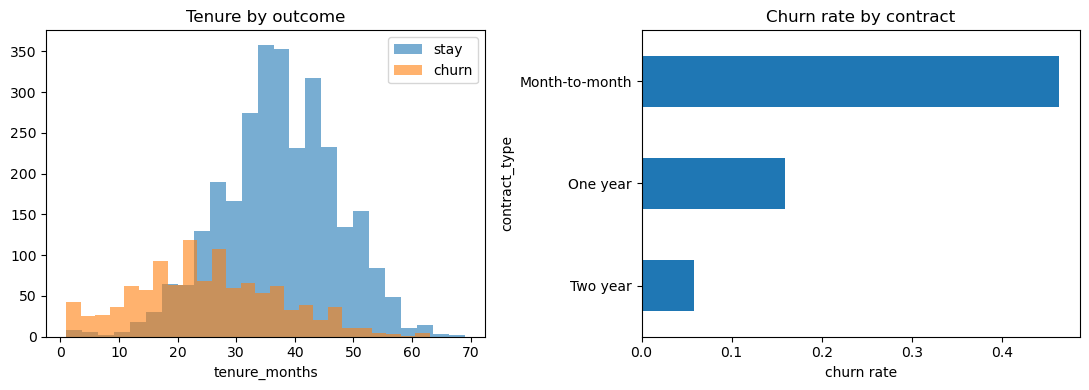

In [2]:
# Class balance
print(df["churn"].value_counts(normalize=True).round(3), "\\n")

# Numeric feature means by outcome
num_cols = [
    "tenure_months", "monthly_charges", "support_tickets",
    "avg_latency_ms", "addons_count", "days_since_login", "total_charges"
]
print(df.groupby("churn")[num_cols].mean().round(1).T, "\\n")

# Churn rate by contract type
print(
    df.groupby("contract_type")["churn"]
      .mean().round(3).sort_values(ascending=False)
)

# Visualise tenure and contract churn rates
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for k, label in [(0, "stay"), (1, "churn")]:
    ax[0].hist(
        df.loc[df.churn == k, "tenure_months"],
        bins=25, alpha=0.6, label=label
    )

ax[0].set_title("Tenure by outcome")
ax[0].set_xlabel("tenure_months")
ax[0].legend()

df.groupby("contract_type")["churn"].mean().sort_values().plot.barh(ax=ax[1])
ax[1].set_title("Churn rate by contract")
ax[1].set_xlabel("churn rate")

plt.tight_layout()
plt.show()

A feature is leakage when its value would not be available at prediction time. exit_survey_sent is a post-outcome flag: the survey is sent because a customer has already churned. It must be removed. total_charges remains because it is cumulative account information available today

In [3]:
from sklearn.model_selection import train_test_split

# Leakage check: inspect absolute numeric correlations with the target.
leak_scores = (
    df.corr(numeric_only=True)["churn"]
      .drop("churn").abs().sort_values(ascending=False)
)
print("Absolute correlation with churn:\\n", leak_scores.round(3), "\\n")

suspects = leak_scores[leak_scores > 0.9].index.tolist()
print("Leakage suspects (correlation > 0.9):", suspects)

# Drop the post-outcome leakage feature.
df_clean = df.drop(columns=suspects)

X = df_clean.drop(columns=["churn"])
y = df_clean["churn"]

# 70% train / 15% validation / 15% test, stratified.
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RNG
)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RNG
)

print("\\nShapes:", X_train.shape, X_val.shape, X_test.shape)
print(
    "Churn rate train/val/test:",
    round(y_train.mean(), 3),
    round(y_val.mean(), 3),
    round(y_test.mean(), 3)
)

Absolute correlation with churn:\n exit_survey_sent    0.947
total_charges       0.566
tenure_months       0.465
support_tickets     0.454
days_since_login    0.419
monthly_charges     0.022
addons_count        0.019
avg_latency_ms      0.004
Name: churn, dtype: float64 \n
Leakage suspects (correlation > 0.9): ['exit_survey_sent']
\nShapes: (2800, 11) (600, 11) (600, 11)
Churn rate train/val/test: 0.275 0.275 0.275


Scale numeric columns and one-hot encode categorical columns. Put preprocessing inside a ColumnTransformer and Pipeline, so each cross-validation fold fits preprocessing only on its training portion.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_features = X_train.select_dtypes(include="number").columns.tolist()
cat_features = X_train.select_dtypes(include="object").columns.tolist()

print("Numeric:", num_features)
print("Categorical:", cat_features)

pre = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

# Sanity check only; model pipelines below independently fit preprocessing.
Z = pre.fit_transform(X_train)
print("\\nTransformed matrix:", Z.shape)
print("Feature count after one-hot:", len(pre.get_feature_names_out()))

Numeric: ['tenure_months', 'monthly_charges', 'support_tickets', 'avg_latency_ms', 'addons_count', 'days_since_login', 'total_charges']
Categorical: ['contract_type', 'payment_method', 'internet_service', 'has_dependents']
\nTransformed matrix: (2800, 19)
Feature count after one-hot: 19


Step 4 — Train and compare four model families

In [5]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

models = {
    "LogReg": LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, random_state=RNG, class_weight="balanced"
    ),
    "GradBoost": GradientBoostingClassifier(random_state=RNG),
    "SVM_RBF": SVC(
        kernel="rbf", probability=True,
        class_weight="balanced", random_state=RNG
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG)
results = {}

for name, clf in models.items():
    pipe = Pipeline([("pre", pre), ("clf", clf)])
    scores = cross_val_score(
        pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1
    )
    results[name] = scores
    print(
        f"{name:13s} ROC-AUC = {scores.mean():.3f} "
        f"+/- {scores.std():.3f}"
    )

comparison = pd.DataFrame({
    name: {"mean_roc_auc": scores.mean(), "std_roc_auc": scores.std()}
    for name, scores in results.items()
}).T.sort_values("mean_roc_auc", ascending=False)

display(comparison)

LogReg        ROC-AUC = 0.938 +/- 0.015
RandomForest  ROC-AUC = 0.938 +/- 0.018
GradBoost     ROC-AUC = 0.940 +/- 0.013
SVM_RBF       ROC-AUC = 0.941 +/- 0.012


,mean_roc_auc,std_roc_auc
SVM_RBF,0.940667,0.012447
GradBoost,0.939939,0.012766
LogReg,0.938138,0.014820
RandomForest,0.937613,0.018468


Gradient Boosting is carried into tuning, while Logistic Regression is retained as an interpretable baseline. The validation set is used only for a confirmatory check after tuning.

In [6]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score

gb_pipe = Pipeline([
    ("pre", pre),
    ("clf", GradientBoostingClassifier(random_state=RNG))
])

param_grid = {
    "clf__n_estimators": [150, 300],
    "clf__learning_rate": [0.05, 0.1],
    "clf__max_depth": [2, 3],
}

grid = GridSearchCV(
    gb_pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 3))

best_model = grid.best_estimator_
val_auc = roc_auc_score(
    y_val, best_model.predict_proba(X_val)[:, 1]
)
print("Validation ROC-AUC:", round(val_auc, 3))

Best params: {'clf__learning_rate': 0.1, 'clf__max_depth': 2, 'clf__n_estimators': 150}
Best CV ROC-AUC: 0.941
Validation ROC-AUC: 0.94


TEST ROC-AUC: 0.951 \n
              precision    recall  f1-score   support

        stay      0.916     0.954     0.935       435
       churn      0.864     0.770     0.814       165

    accuracy                          0.903       600
   macro avg      0.890     0.862     0.874       600
weighted avg      0.902     0.903     0.902       600



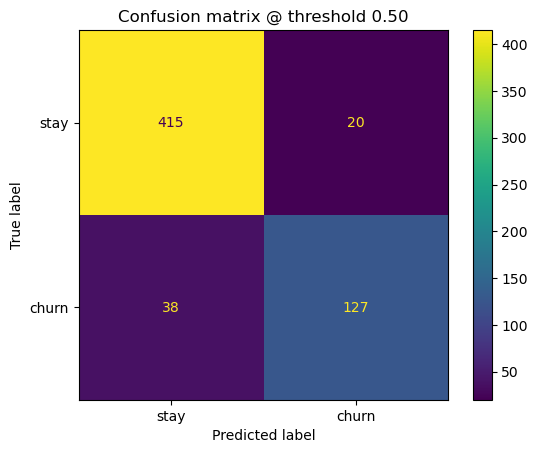

  thr  precision   recall     f1
 0.50      0.864    0.770  0.814
 0.40      0.805    0.800  0.802
 0.35      0.780    0.836  0.807
 0.30      0.728    0.842  0.781
 0.25      0.703    0.861  0.774


In [7]:
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, precision_score, recall_score, f1_score
)

# Final test probabilities from the frozen tuned model.
proba = best_model.predict_proba(X_test)[:, 1]
pred_050 = (proba >= 0.50).astype(int)

print("TEST ROC-AUC:", round(roc_auc_score(y_test, proba), 3), "\\n")
print(classification_report(
    y_test, pred_050, target_names=["stay", "churn"], digits=3
))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_050),
    display_labels=["stay", "churn"]
).plot(values_format="d")
plt.title("Confusion matrix @ threshold 0.50")
plt.show()

# Threshold trade-off table (descriptive comparison).
print(f"{'thr':>5} {'precision':>10} {'recall':>8} {'f1':>6}")
for t in [0.50, 0.40, 0.35, 0.30, 0.25]:
    pred = (proba >= t).astype(int)
    print(
        f"{t:5.2f} "
        f"{precision_score(y_test, pred):10.3f} "
        f"{recall_score(y_test, pred):8.3f} "
        f"{f1_score(y_test, pred):6.3f}"
    )

Permutation importance (ROC-AUC drop when shuffled):
total_charges       0.1045
contract_type       0.0525
support_tickets     0.0370
internet_service    0.0186
payment_method      0.0179
monthly_charges     0.0094
has_dependents      0.0082
tenure_months       0.0027
addons_count        0.0014
days_since_login    0.0013
avg_latency_ms     -0.0004
dtype: float64 \n
Most churn-driving (positive coefficient):\n
cat__internet_service_Fiber optic       0.72
num__support_tickets                    0.92
cat__payment_method_Electronic check    0.94
cat__contract_type_Month-to-month       1.28
dtype: float64 \n
Most protective (negative coefficient):\n
num__tenure_months            -1.76
num__monthly_charges          -1.34
cat__contract_type_Two year   -1.14
cat__internet_service_None    -0.81
dtype: float64


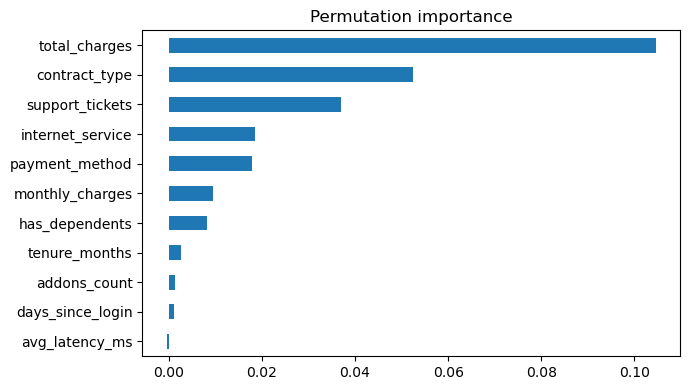

In [8]:
from sklearn.inspection import permutation_importance

# Permutation importance on validation data.
perm = permutation_importance(
    best_model, X_val, y_val,
    n_repeats=8, random_state=RNG, scoring="roc_auc"
)

imp = pd.Series(
    perm.importances_mean, index=X.columns
).sort_values(ascending=False)

print("Permutation importance (ROC-AUC drop when shuffled):")
print(imp.round(4), "\\n")

# Signed drivers from an interpretable Logistic Regression baseline.
logreg = Pipeline([
    ("pre", pre),
    ("clf", LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ))
]).fit(X_train, y_train)

coef = pd.Series(
    logreg.named_steps["clf"].coef_[0],
    index=logreg.named_steps["pre"].get_feature_names_out()
)

print("Most churn-driving (positive coefficient):\\n")
print(coef.sort_values().tail(4).round(2), "\\n")
print("Most protective (negative coefficient):\\n")
print(coef.sort_values().head(4).round(2))

imp.sort_values().plot.barh(
    figsize=(7, 4), title="Permutation importance"
)
plt.tight_layout()
plt.show()

In [9]:
# Operating threshold used for the business illustration.
OPERATING_THRESHOLD = 0.30
p30 = (proba >= OPERATING_THRESHOLD).astype(int)

summary = {
    "primary_metric": "Recall on churn (ROC-AUC for model selection)",
    "chosen_model": "GradientBoosting (tuned)",
    "test_roc_auc": round(roc_auc_score(y_test, proba), 3),
    "operating_threshold": OPERATING_THRESHOLD,
    "recall_at_0.30": round(recall_score(y_test, p30), 3),
    "precision_at_0.30": round(precision_score(y_test, p30), 3),
    "top_drivers": imp.head(3).index.tolist(),
}

for key, value in summary.items():
    print(f"{key:22s}: {value}")

primary_metric        : Recall on churn (ROC-AUC for model selection)
chosen_model          : GradientBoosting (tuned)
test_roc_auc          : 0.951
operating_threshold   : 0.3
recall_at_0.30        : 0.842
precision_at_0.30     : 0.728
top_drivers           : ['total_charges', 'contract_type', 'support_tickets']


Example manager recommendation
The tuned Gradient Boosting model provides a useful ranking of customers by churn risk, with the test ROC-AUC and threshold-specific precision/recall shown in the scorecard above. A 0.30 alert threshold prioritises catching more likely churners, but it will also generate more false alarms and should be adopted only if the value of a retained customer justifies the additional save-offers. The retention team should prioritise customers with short tenure, month-to-month contracts, and high support-ticket counts, then test proactive support and annual-contract incentives. Before deployment, validate the threshold against the actual cost of missed churners and unnecessary offers, and monitor performance over time.
Reflection
1. Leakage: A real churn table could contain cancellation_date, account_closed_reason, or a final bill status recorded only after cancellation. I would check when each field becomes available, inspect suspiciously strong relationships with the target, and compare performance after removing post-outcome fields.

2. Metric choice: Precision matters more when contacting a customer is expensive or when an unnecessary discount damages margin. For example, if every retention offer is a costly high-value incentive, the business may prefer fewer alerts that are more likely to churn.

3. Trust: I would favour a model that offers similar ROC-AUC with lower operating cost, simpler maintenance, and clearer explanations. When four model families perform almost identically, better features, cleaner labels, more representative data, and better intervention feedback are likely to offer more improvement than switching algorithms.

4. Honesty: If I used the test set to choose the threshold and then reported performance on that same test set, I would indirectly optimise decisions for that test sample. The reported result would be biased upward and would no longer be an independent estimate of performance on unseen customers.